<a href="https://colab.research.google.com/github/Dhanya-gowda24/ML_Lab_NIE/blob/main/PCA_and_LDA(lab7).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

    study_hours  attendance  assignment_marks  internal_marks  \
0             1          50                30              25   
1             2          55                35              30   
2             2          60                32              28   
3             3          58                38              32   
4             2          52                33              27   
5             3          62                40              35   
6             1          48                28              24   
7             2          57                36              31   
8             3          63                39              34   
9             2          54                34              29   
10            4          70                50              45   
11            5          75                55              48   
12            4          72                52              46   
13            5          78                58              52   
14            6          

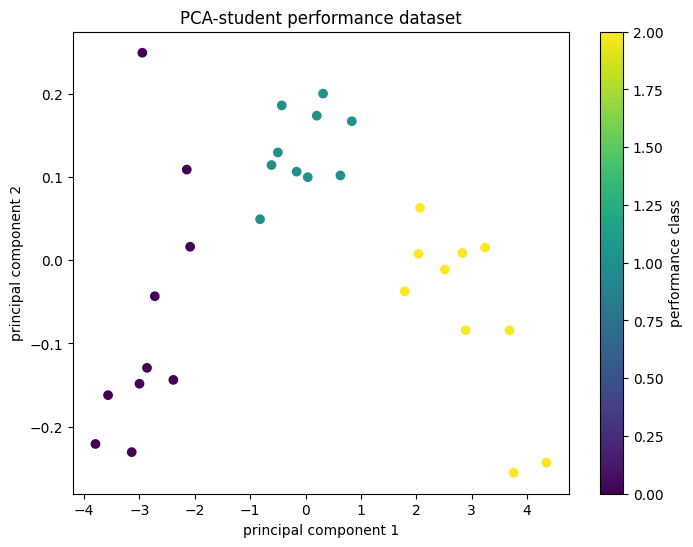

Original Shape: (30, 6)
reduce shape: (30, 2)


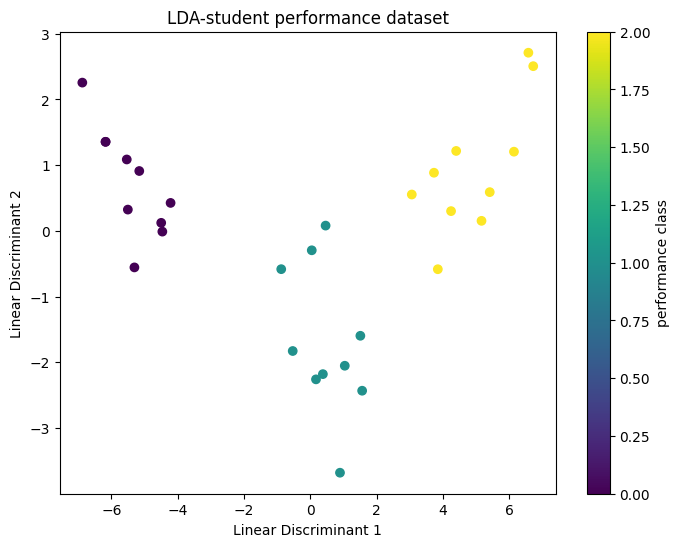

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

data={
    'study_hours':[
        1,2,2,3,2,3,1,2,3,2,
        4,5,4,5,6,4,5,6,5,4,
        7,8,7,9,8,7,9,8,10,9
    ],

    'attendance':[
        50,55,60,58,52,62,48,57,63,54,70,75,72,78,80,74,76,82,79,73,85,90,88,95,92,87,96,91,98,94
    ],

    'assignment_marks':[
        30,35,32,38,33,40,28,36,39,34,
        50,55,52,58,60,54,57,62,59,53,70,75,72,80,78,73,85,79,90,86
    ],

    'internal_marks':[
        25,30,28,32,27,35,24,31,34,29,45,48,46,52,55,47,50,56,53,49,65,70,68,75,73,67,80,74,85,82
    ],

    'practical_marks':[
        28,32,30,35,29,37,25,33,36,31,48,52,50,55,58,51,54,60,56,49,68,73,70,78,76,69,82,77,88,84
    ],

    'test_marks':[
        20,25,22,28,24,30,18,26,29,23,40,45,42,48,50,44,47,52,49,43,60,65,62,70,68,63,75,69,80,76
    ],

    'performance':[
        0,0,0,0,0,0,0,0,0,0,
        1,1,1,1,1,1,1,1,1,1,
        2,2,2,2,2,2,2,2,2,2
    ]
}
df=pd.DataFrame(data)
print(df)

X=df.drop('performance',axis=1)
y=df['performance']
print("input shape:",X.shape)
print("output shape:",y.shape)

scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)
print("Standardized data:")
print(X_scaled[:5])

#applying pca-reduce 6 features into two components
pca=PCA(n_components=2)
X_pca=pca.fit_transform(X_scaled)
print("Original Shape:",X_scaled.shape)
print("reduce shape:",X_pca.shape)

#display explaines variance
print("explained variance ratio:")
print(pca.explained_variance_ratio_)
print("total explained variance:")
print(sum(pca.explained_variance_ratio_))

#visualize pca results
plt.figure(figsize=(8,6))
plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=y,
    cmap='viridis'
)
plt.xlabel("principal component 1")
plt.ylabel("principal component 2")
plt.title("PCA-student performance dataset")
plt.colorbar(label='performance class')
plt.show()

#applying LDA
lda=LinearDiscriminantAnalysis(n_components=2)
X_lda=lda.fit_transform(X_scaled,y)
print("Original Shape:",X_scaled.shape)
print("reduce shape:",X_pca.shape)

#visualize lda results
plt.figure(figsize=(8,6))
plt.scatter(
    X_lda[:,0],
    X_lda[:,1],
    c=y,
    cmap='viridis'
)
plt.xlabel("Linear Discriminant 1")
plt.ylabel("Linear Discriminant 2")
plt.title("LDA-student performance dataset")
plt.colorbar(label='performance class')
plt.show()